# 08. Повторная проверка на test: подтверждаются ли доработки 06–07?

**Это повторное использование test.** Первый результат —  `05_final_comparison`. Здесь проверяем, подтверждаются ли на test две вещи, найденные после финала только на val:

1. **Усреднение по seed** (`07_seeds`): на val_b оно изменило вывод про E2 (значимо → незначимо). Совпадёт ли усреднённый результат с test?
2. **LambdaRank** (`06_hyperparams`): на val он лучше бинарного logloss у всех 5 наборов. Улучшает ли он ранжирование на test?

**Протокол:**
- модели: (1) базовые параметры, seed 42 / 1 / 2, прогнозы усредняются; (2) LambdaRank, seed 42 — для всех 5 наборов;
- обучение как в 06–07: train, ранняя остановка по val_a;
- сравнения: набор − E0 , LambdaRank − базовая модель того же набора; парный бутстреп по группам «пользователь × день» (1000 повторов, 95% ДИ), как в 05;
- контроль: seed 42 базовой модели должен воспроизвести прогнозы `artifacts/final_test.pkl`.

20 обучений, ~25 мин, пик памяти ~3.5 ГБ. Прогнозы сохраняются в `artifacts/test_recheck/` после каждого обучения: если WSL упадёт, при перезапуске готовые пропускаются.

In [1]:
import sys, time, resource, pickle, gc
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import polars as pl
import lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from IPython.display import display, Markdown

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(20)
pl.Config.set_fmt_str_lengths(60)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def peak_ram_gb():
    """Пиковая память процесса (ядра ноутбука) с момента старта, ГБ."""
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024**2

from src.candidates import load_candidates
from src.selection import catalog, load_matrix
from src.decay import load_decay
from src.metrics import evaluate, ranking_metrics
from src.models import LGB_PARAMS, MAX_ROUNDS, EARLY_STOP, train_lgb
from src import memguard

ART = ROOT / "artifacts" / "test_recheck"
ART.mkdir(parents=True, exist_ok=True)
res0, res1, res2 = (pickle.load(open(ROOT / "artifacts" / e / "results.pkl", "rb")) for e in ["E0", "E1", "E2"])
final = pickle.load(open(ROOT / "artifacts" / "final_test.pkl", "rb"))
SEEDS = [42, 1, 2]

## 1. Данные

Те же пять наборов и тот же способ загрузки, что в 06–07. Нужны train (обучение), val_a (ранняя остановка) и test (оценка); val_b здесь не нужен, его не загружаем ради памяти.

In [ ]:
SETS = {
    "E0": res0["features"],
    "E1": res1["features"],
    "E0 + E1": res1["union_features"],
    "E2": res2["features"],
    "E0 + E2": [*res0["features"], *res2["features"]],
}
ALL = list(dict.fromkeys(f for cols in SETS.values() for f in cols))
E1_ONLY = [f for f in res1["features"] if f not in res0["features"]]

memguard.check(3.5, "загрузка признаков")
cands = load_candidates()
cat = catalog()
feats0 = pl.read_parquet(ROOT / "data" / "processed" / "features_E0.parquet")

t0 = time.perf_counter()
M, y, META = {}, {}, {}
for part in ["train", "val_a", "test"]:
    d = cands.filter(pl.col("part") == part)
    m = (load_matrix(d, E1_ONLY, cat)
         .join(load_decay(d, res2["config"]), on="row_id", how="left", maintain_order="left")
         .join(feats0, on="row_id", how="left", maintain_order="left"))
    # метки сопоставляются по позиции — порядок строк обязан совпадать (polars 2.0 join не сохраняет порядок)
    assert m["row_id"].equals(d["row_id"])
    
    M[part] = m.select(ALL).cast(pl.Float32).to_numpy()
    y[part] = d["label"].to_numpy()
    META[part] = d.select("row_id", "uid", "day", "label")
    del m, d
    gc.collect()


del cands, feats0
gc.collect()
COL = {f: i for i, f in enumerate(ALL)}
print(f"загрузка {time.perf_counter() - t0:.0f} с; пиковая память {peak_ram_gb():.1f} ГБ")

загрузка 8 с; пиковая память 3.7 ГБ


## 2. Обучение

Для каждого набора: базовая модель с seed 42, 1, 2 и LambdaRank с seed 42. Параметры и ранняя остановка — как в 06–07. Сохраняем только прогнозы на test.

In [ ]:
def group_sizes(meta):
    """Размеры групп «пользователь × день» в порядке строк (строки группы идут подряд)"""
    runs = meta.select((pl.struct("uid", "day") != pl.struct("uid", "day").shift()).fill_null(True).cum_sum().alias("g"))
    sizes = runs.group_by("g", maintain_order=True).len()["len"].to_numpy()
    assert len(sizes) == meta.select("uid", "day").unique().height, "группы идут не подряд"
    return sizes


GROUPS = {p: group_sizes(META[p]) for p in ["train", "val_a"]}
RANK_PARAMS = {"objective": "lambdarank", "metric": "ndcg", "eval_at": [10]}


def train_rank(X_tr, y_tr, X_va, y_va):
    """LambdaRank, как в 06: те же параметры деревьев, ранняя остановка по NDCG@10 на val_a"""
    params = {**LGB_PARAMS, **RANK_PARAMS}
    dtr = lgb.Dataset(X_tr, y_tr, group=GROUPS["train"], free_raw_data=True)
    dva = lgb.Dataset(X_va, y_va, group=GROUPS["val_a"], reference=dtr)
    t0 = time.perf_counter()
    model = lgb.train(params, dtr, num_boost_round=MAX_ROUNDS, valid_sets=[dva], valid_names=["val_a"],
                      callbacks=[lgb.early_stopping(EARLY_STOP, verbose=False)])
    return model, time.perf_counter() - t0


RUNS = [(s, "base", seed) for s in SETS for seed in SEEDS] + [(s, "lambdarank", 42) for s in SETS]


def pred_path(s, kind, seed):
    return ART / f"pred_{s}_{kind}_seed{seed}.parquet"


cost = {}
for s, kind, seed in RUNS:
    if pred_path(s, kind, seed).exists():
        continue
    
    memguard.check(1.5, f"{s} {kind} {seed}")
    idx = [COL[f] for f in SETS[s]]
    X_va = M["val_a"][:, idx]
    
    if kind == "lambdarank":
        model, sec = train_rank(M["train"][:, idx], y["train"], X_va, y["val_a"])
    else:
        model, _, sec = train_lgb(M["train"][:, idx], y["train"], X_va, y["val_a"], {"seed": seed})
    
    cost[f"{s}|{kind}|{seed}"] = sec
    META["test"].select("row_id").with_columns(p=pl.Series(model.predict(M["test"][:, idx]))).write_parquet(pred_path(s, kind, seed))
    
    print(f"{s:8s} {kind:10s} seed {seed:2d}: деревьев {model.best_iteration}, {sec:.0f} с, память {peak_ram_gb():.1f} ГБ", flush=True)
    del model, X_va
    gc.collect()


del M
_ = gc.collect()

E0       base       seed 42: деревьев 253, 51 с, память 3.7 ГБ


E0       base       seed  1: деревьев 343, 54 с, память 3.7 ГБ


E0       base       seed  2: деревьев 282, 49 с, память 3.7 ГБ


E1       base       seed 42: деревьев 123, 20 с, память 3.7 ГБ


E1       base       seed  1: деревьев 164, 23 с, память 3.7 ГБ


...

E0       lambdarank seed 42: деревьев 303, 73 с, память 3.8 ГБ


E1       lambdarank seed 42: деревьев 207, 42 с, память 3.8 ГБ


E0 + E1  lambdarank seed 42: деревьев 308, 81 с, память 3.8 ГБ


E2       lambdarank seed 42: деревьев 148, 61 с, память 3.8 ГБ


E0 + E2  lambdarank seed 42: деревьев 193, 93 с, память 3.8 ГБ


## 3. Контроль: seed 42 воспроизводит финальный прогон

Базовая модель с seed 42 — это ровно модель из `05_final_comparison`. Её прогнозы на test должны совпасть с сохранёнными в `final_test.pkl`; иначе сравнение с основной таблицей некорректно.

In [4]:
P = {}
for s, kind, seed in RUNS:
    p = pl.read_parquet(pred_path(s, kind, seed))
    assert p["row_id"].equals(META["test"]["row_id"])
    P[(s, kind, seed)] = p["p"].to_numpy()

fp = META["test"].select("row_id").join(final["predictions"], on="row_id", how="left", maintain_order="left")
repro = pl.DataFrame([{"набор": s, "макс. |разница| прогнозов": float(np.abs(P[(s, "base", 42)] - fp[f"{s} LightGBM"].to_numpy()).max())}
                      for s in SETS])
repro

набор,макс. |разница| прогнозов
str,f64
"""E0""",0.0
"""E1""",0.0
"""E0 + E1""",0.0
"""E2""",0.0
"""E0 + E2""",0.0


## 4. Метрики на test

- **seed 42** — модель из основной таблицы (05);
- **среднее 3 seed** — прогнозы трёх seed усреднены;
- **LambdaRank** — скор не вероятность, поэтому LogLoss и ROC-AUC не считаем.

In [ ]:
def metrics(p, rank=False):
    df = META["test"].with_columns(p=pl.Series(p))
    if rank:
        return {"logloss": None, "roc_auc": None, **ranking_metrics(df, "p")}
    return evaluate(df, "p")


AVG = {s: np.mean([P[(s, "base", seed)] for seed in SEEDS], axis=0) for s in SETS}
rows = []
for s in SETS:
    for kind, p, rank in [("seed 42 (05)", P[(s, "base", 42)], False), ("среднее 3 seed", AVG[s], False),
                          ("LambdaRank", P[(s, "lambdarank", 42)], True)]:
        r = metrics(p, rank)
        rows.append({"набор": s, "модель": kind, **{k: r[k] for k in ["logloss", "roc_auc", "gauc", "ndcg@10", "recall@10"]}})
test_tab = pl.DataFrame(rows)

per_seed = pl.DataFrame([{"набор": s, "seed": seed, "gauc": metrics(P[(s, "base", seed)])["gauc"]} for s in SETS for seed in SEEDS])


display(test_tab.with_columns(pl.col(pl.Float64).round(4)))
display(per_seed.pivot(on="seed", index="набор", values="gauc")
        .with_columns(pl.concat_list(pl.exclude("набор")).list.std().alias("std по seed")).with_columns(pl.col(pl.Float64).round(4)))

набор,модель,logloss,roc_auc,gauc,ndcg@10,recall@10
str,str,f64,f64,f64,f64,f64
"""E0""","""seed 42 (05)""",0.4553,0.8228,0.573,0.7708,0.5074
"""E0""","""среднее 3 seed""",0.4554,0.8232,0.5743,0.7713,0.5077
"""E0""","""LambdaRank""",null,null,0.5759,0.7747,0.5083
"""E1""","""seed 42 (05)""",0.4563,0.8188,0.5684,0.768,0.5066
"""E1""","""среднее 3 seed""",0.4561,0.819,0.569,0.7679,0.5067
"""E1""","""LambdaRank""",null,null,0.5717,0.7705,0.5072
"""E0 + E1""","""seed 42 (05)""",0.4504,0.8259,0.5754,0.772,0.5087
"""E0 + E1""","""среднее 3 seed""",0.4493,0.8265,0.5755,0.7725,0.5093
"""E0 + E1""","""LambdaRank""",null,null,0.5792,0.7758,0.5093


набор,42,1,2,std по seed
str,f64,f64,f64,f64
"""E0""",0.573,0.5728,0.5741,0.0007
"""E1""",0.5684,0.5686,0.5684,0.0001
"""E0 + E1""",0.5754,0.5745,0.5766,0.001
"""E2""",0.5722,0.5724,0.5718,0.0003
"""E0 + E2""",0.5757,0.5762,0.5762,0.0003


## 5. Разности с E0 и LambdaRank против базовой модели (парный бутстреп)

Для каждой пары считаем разность GAUC в каждой группе «пользователь × день» и 95% интервал для средней разности (1000 повторов, те же индексы групп для всех сравнений).

In [ ]:
def group_gauc(d, col):
    return (d.with_columns(r=pl.col(col).rank("average").over("uid", "day"),
                           npos=pl.col("label").sum().over("uid", "day"), n=pl.len().over("uid", "day"))
            .filter((pl.col("npos") > 0) & (pl.col("npos") < pl.col("n")))
            .group_by("uid", "day")
            .agg(g=((pl.col("r") * pl.col("label")).sum() - pl.col("npos").first() * (pl.col("npos").first() + 1) / 2)
                 / (pl.col("npos").first() * (pl.col("n").first() - pl.col("npos").first())))
            .sort("uid", "day")["g"].to_numpy())


G = {}
for s in SETS:
    for kind, p in [("seed 42", P[(s, "base", 42)]), ("среднее 3 seed", AVG[s]), ("LambdaRank", P[(s, "lambdarank", 42)])]:
        G[(s, kind)] = group_gauc(META["test"].with_columns(p=pl.Series(p)), "p")
n_groups = len(G[("E0", "seed 42")])
idx = np.random.default_rng(0).integers(0, n_groups, (1000, n_groups))


def boot_row(name, kind, a, b):
    d = a - b
    lo, hi = np.quantile(d[idx].mean(1), [0.025, 0.975])
    return {"сравнение": name, "модели": kind, "Δ GAUC": d.mean(), "ДИ низ": lo, "ДИ верх": hi,
            "значимо": "да" if lo > 0 or hi < 0 else "нет"}


boot = []
for s in [s for s in SETS if s != "E0"]:
    for kind in ["seed 42", "среднее 3 seed", "LambdaRank"]:
        boot.append(boot_row(f"{s} − E0", kind, G[(s, kind)], G[("E0", kind)]))
for s in SETS:
    boot.append(boot_row(f"{s}: LambdaRank − база", "LambdaRank − среднее 3 seed", G[(s, "LambdaRank")], G[(s, "среднее 3 seed")]))

boot = pl.DataFrame(boot)
display(boot.with_columns(pl.col(pl.Float64).round(4)))

сравнение,модели,Δ GAUC,ДИ низ,ДИ верх,значимо
str,str,f64,f64,f64,str
"""E1 − E0""","""seed 42""",-0.0046,-0.0073,-0.0021,"""да"""
"""E1 − E0""","""среднее 3 seed""",-0.0053,-0.008,-0.0026,"""да"""
"""E1 − E0""","""LambdaRank""",-0.0042,-0.0069,-0.0014,"""да"""
"""E0 + E1 − E0""","""seed 42""",0.0024,0.0004,0.0046,"""да"""
"""E0 + E1 − E0""","""среднее 3 seed""",0.0013,-0.0006,0.0033,"""нет"""
"""E0 + E1 − E0""","""LambdaRank""",0.0033,0.0013,0.0053,"""да"""
"""E2 − E0""","""seed 42""",-0.0008,-0.0032,0.0018,"""нет"""
"""E2 − E0""","""среднее 3 seed""",-0.0014,-0.0038,0.001,"""нет"""
"""E2 − E0""","""LambdaRank""",0.0002,-0.0024,0.003,"""нет"""


In [ ]:
# Знак разности с E0 при каждом seed отдельно (одинаковый seed у обоих наборов)
sign = (per_seed.filter(pl.col("набор") != "E0")
        .join(per_seed.filter(pl.col("набор") == "E0").select("seed", pl.col("gauc").alias("g0")), on="seed", how="left")
        .with_columns((pl.col("gauc") - pl.col("g0")).alias("Δ"))
        .pivot(on="seed", index="набор", values="Δ")
        .with_columns(pl.min_horizontal([str(s) for s in SEEDS]).alias("мин"), pl.max_horizontal([str(s) for s in SEEDS]).alias("макс")))

display(sign.with_columns(pl.col(pl.Float64).round(4)))

набор,42,1,2,мин,макс
str,f64,f64,f64,f64,f64
"""E1""",-0.0046,-0.0042,-0.0058,-0.0058,-0.0042
"""E0 + E1""",0.0024,0.0018,0.0025,0.0018,0.0025
"""E2""",-0.0008,-0.0003,-0.0023,-0.0023,-0.0003
"""E0 + E2""",0.0027,0.0034,0.0021,0.0021,0.0034


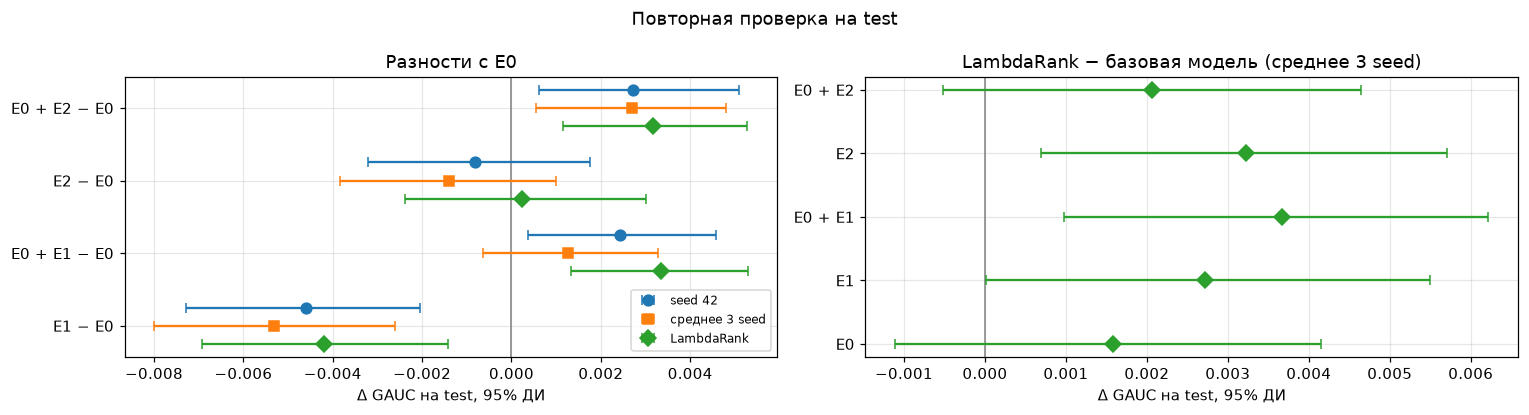

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
others = [s for s in SETS if s != "E0"]
kinds = [("seed 42", "C0", "o"), ("среднее 3 seed", "C1", "s"), ("LambdaRank", "C2", "D")]

ax = axes[0]
ax.axvline(0, color="0.5", lw=1)

for j, s in enumerate(others):
    for k, (kind, c, mk) in enumerate(kinds):
        b = boot.filter((pl.col("сравнение") == f"{s} − E0") & (pl.col("модели") == kind)).row(0, named=True)
        ax.errorbar(b["Δ GAUC"], j + 0.25 - 0.25 * k, xerr=[[b["Δ GAUC"] - b["ДИ низ"]], [b["ДИ верх"] - b["Δ GAUC"]]],
                    fmt=mk, color=c, ms=7, capsize=3, label=kind if j == 0 else None)

ax.set_yticks(range(len(others)), [f"{s} − E0" for s in others])
ax.set_xlabel("Δ GAUC на test, 95% ДИ")
ax.set_title("Разности с E0")
ax.legend(loc="lower right", fontsize=8)

ax = axes[1]
ax.axvline(0, color="0.5", lw=1)
sets = list(SETS)

for j, s in enumerate(sets):
    b = boot.filter(pl.col("сравнение") == f"{s}: LambdaRank − база").row(0, named=True)
    ax.errorbar(b["Δ GAUC"], j, xerr=[[b["Δ GAUC"] - b["ДИ низ"]], [b["ДИ верх"] - b["Δ GAUC"]]], fmt="D", color="C2", ms=7, capsize=3)

ax.set_yticks(range(len(sets)), sets)
ax.set_xlabel("Δ GAUC на test, 95% ДИ")
ax.set_title("LambdaRank − базовая модель (среднее 3 seed)")
fig.suptitle("Повторная проверка на test")
plt.tight_layout()
plt.show()

## 6. Выводы


1. **Контроль пройден.** Базовые модели с seed 42 воспроизводят прогнозы `final_test.pkl` точно (разница 0.0)
2. **Самый устойчивый вывод — E0 + E2 лучше E0.** Значимо при всех трёх способах  и положительно при каждом seed отдельно (+0.0021…+0.0034)
3. **E1 хуже E0 — тоже устойчиво.** Значимо при всех трёх способах (−0.0042…−0.0053) и при каждом seed.
4. **E2 и E0 не различаются** при любом способе. Это ровно то, что предсказало усреднение по seed на val_b (`07_seeds`), а не одиночный seed 42 
5. **E0 + E1 лучше E0 — слабее, чем в основной таблице.** Знак положительный при каждом seed , но при усреднении трёх seed разница +0.0013 [−0.0006; +0.0033] уже незначима: E0 от усреднения выиграл больше, чем E0 + E1. С LambdaRank значимо 
6. **LambdaRank подтвердился на test.** Он лучше базовой модели (усреднённой по 3 seed) у всех 5 наборов. Лучшие GAUC на test — LambdaRank на E0 + E1  и E0 + E2 
7. **Не подтвердилось:** на val LambdaRank сильнее всего помогал E0 (+0.0042 на val_b), на test у E0 прирост наименьший (+0.0016). Наблюдение «LambdaRank помогает ручным признакам больше» из `06_hyperparams` было шумом.
8. **Оговорка о воспроизводимости LambdaRank.** Для E0 + E2 ранняя остановка здесь сработала на 193 деревьях, а в `06_hyperparams` — на 363 при тех же данных и параметрах; у остальных наборов число деревьев совпало. Вероятная причина — многопоточный LambdaRank в LightGBM не детерминирован (параметр `deterministic` не включён); бинарные модели воспроизводятся точно. Причину мы не проверяли.

**Итог:** основные выводы финала подтверждаются, но с поправками: «E0 + E2 > E0» и «E1 < E0» устойчивы ко всему; «E0 + E1 > E0» держится по знаку, но его значимость зависит от seed; LambdaRank улучшает ранжирование на всех наборах. Таблица `05_final_comparison` остаётся основной.

In [9]:
results = {"protocol": "08_test_recheck, раздел 1 (зафиксирован до запуска)", "runs": RUNS, "reproducibility": repro, "test_metrics": test_tab,
           "per_seed": per_seed, "bootstrap": boot, "sign_by_seed": sign,
           "cost": {"train_s": cost, "peak_ram_gb": peak_ram_gb()}}
with open(ART / "results.pkl", "wb") as f:
    pickle.dump(results, f)
display(results["cost"])

{'train_s': {'E0|base|42': 50.97199986100168,
  'E0|base|1': 54.403380915002344,
  'E0|base|2': 49.027310581001075,
  'E1|base|42': 20.050703672000964,
  'E1|base|1': 23.20152020399837,
  'E1|base|2': 21.05386627700136,
  'E0 + E1|base|42': 50.833341176999966,
  'E0 + E1|base|1': 57.89268258199809,
  'E0 + E1|base|2': 59.47530777399879,
  'E2|base|42': 64.96320346200082,
  'E2|base|1': 49.99981337099962,
  'E2|base|2': 45.61003271699883,
  'E0 + E2|base|42': 91.79484467899965,
  'E0 + E2|base|1': 102.65296457700242,
  'E0 + E2|base|2': 89.16696400399815,
  'E0|lambdarank|42': 72.61761877699973,
  'E1|lambdarank|42': 41.862301037999714,
  'E0 + E1|lambdarank|42': 80.95521358699989,
  'E2|lambdarank|42': 61.45750499800124,
  'E0 + E2|lambdarank|42': 93.23118862200135},
 'peak_ram_gb': 3.8104324340820312}